In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns", 30)
data = pd.read_csv('train.csv')

In [2]:
data

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,False,True,False,True,False,False,False,True,False,False,True,False,False,False,True,0
1,72295,75.0,1,0,215.17,48.0,True,False,False,False,True,False,False,False,True,False,True,False,False,True,False,0
2,26451,15.0,0,0,135.22,19.0,False,True,False,True,False,False,False,True,False,False,True,False,False,True,False,0
3,65210,47.0,0,0,64.89,28.2,False,True,False,False,True,False,False,False,True,False,False,True,False,True,False,0
4,69299,49.0,0,0,222.34,28.8,False,True,False,False,True,False,False,False,True,False,True,False,True,False,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33545,71911,9.0,0,0,109.80,14.5,False,True,False,True,False,False,False,False,False,True,True,False,False,False,False,0
33546,19648,47.0,0,0,88.61,30.8,True,False,False,False,True,False,False,True,False,False,False,True,False,False,False,0
33547,35550,3.0,0,0,89.68,16.2,True,False,False,True,False,False,False,False,False,True,True,False,False,False,False,0
33548,65453,56.0,1,0,82.44,27.8,True,False,False,False,True,True,False,False,False,False,False,True,False,False,True,0


## Opschonen


### Kolommen

Het model moet gefit worden op data die zo schoon mogelijk is. De features behoren geen ruis te geven. Daarom kijken we naar twee onderdelen

- Onmogelijke correlatie

Sommige informatie kan onmogelijk correleren, of zou niet moeten correleren met de predictor. In dit geval is het de ID kolom. Dit zijn willekeurige cijfers om elke rij te identificeren, alleen het model zal hier patronen proberen te ontdekken die niet bestaan, dit noem je ruis. Om deze reden zullen we de ID kolom weghalen



- Multicolineariteit

Kolommen die naar dummys worden omgezet hebben standaard een sterke correlatie met elkaar --> als het ene waar is, is het andere niet waar --> sterke negatieve correlatie. Dit zorgt ervoor dat de dummykolomen een sterkere weging krijgen zonder dat dat de bedoeling is. We kunnen dit voorkomen door per onderscheiding één klasse weg te halen, waardoor de ontbrekende klasse van toepassing is als de overige 'False' geven. Hieronder is een overzicht gemaakt van de klassen per variabele.


| Variabele | Categorieën |
|---|---|
| **Gender** | `gender_male`, `gender_female`, `gender_other` |
| **ever_married** | `ever_married_No`, `ever_married_Yes` |
| **work_type** | `Govt_job`, `Never_worked`, `Private`, `Self-employed`, `children` |
| **Residence_type** | `Rural`, `Urban` |
| **smoking_status** | `formerly_smoked`, `never_smoked`, `smokes`, `unknown` |

Bij de beschrijving van de opdracht is er aangegeven dat smoking_status al een verwijderde kolom heeft. Daarom hoeft deze variabele niet aangepast te worden.

In [3]:
dropcols = ['id', 'gender_Male', 'ever_married_No', 'work_type_Govt_job', 'Residence_type_Rural']

### Rijen

Om irrelevante rijen te verwijderen kijken we weer naar twee onderdelen

- Missende waarden door geen datagerelateerde reden --> MCAR

De dataset bevat geen missende waarden, dus hier hoeft niks aan te gebeuren.


- Onmogelijke/foute waarden

Hierbij kijken we of er extreem hoge/lage waarden zijn


Zoals je hieronder kunt zien zijn alle histplots redelijk normaal. Er zijn geen extreme (onrealistische) uitschieters met onmogelijke waarden. 

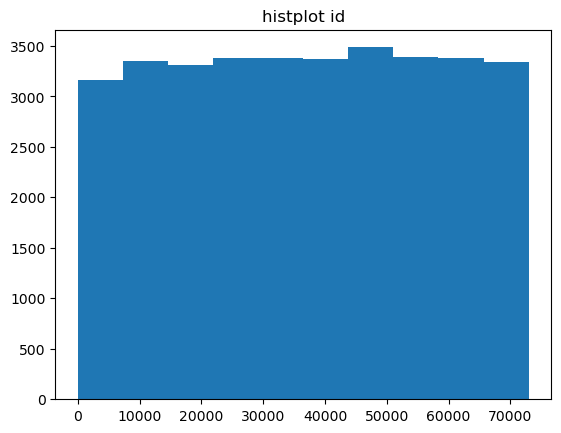

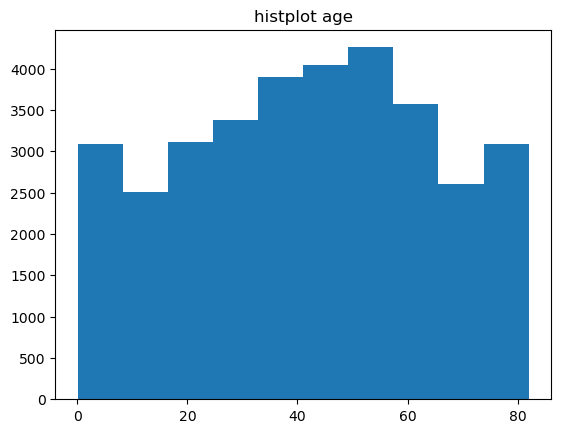

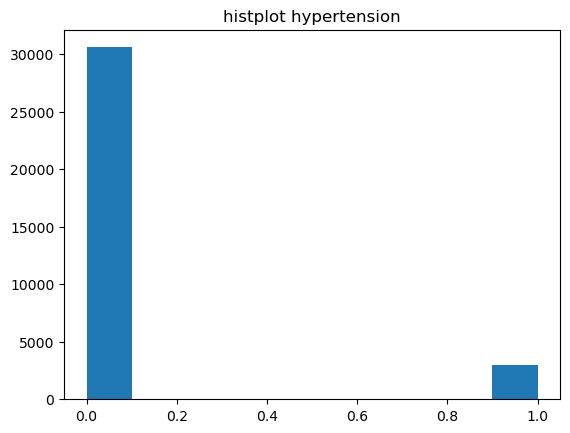

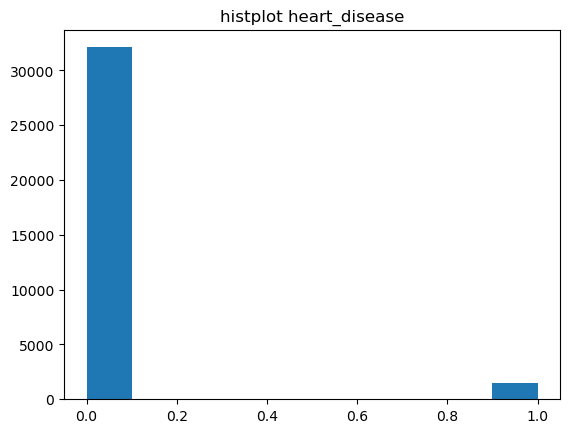

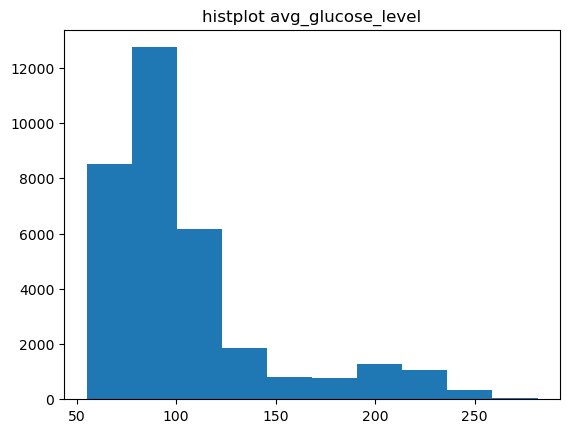

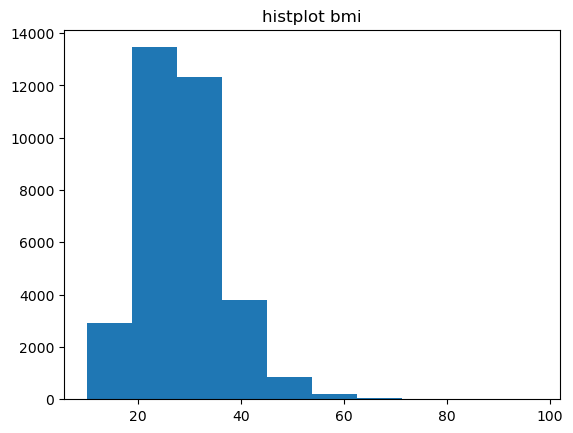

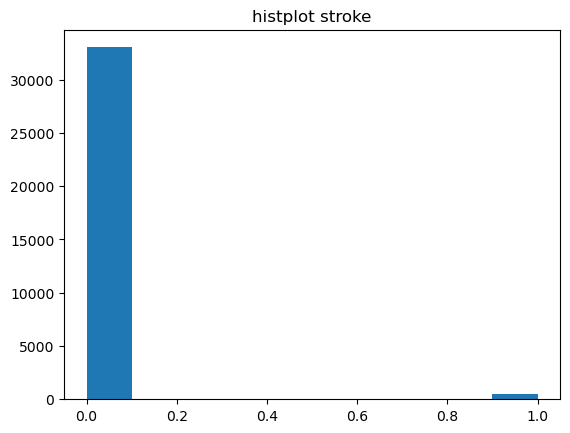

In [4]:
for i in data.select_dtypes(include=["integer", "floating"]).columns:
    plt.hist(data[i])
    plt.title(f"histplot {i}")
    plt.show()

## Standaardiseren

- Wat is standaardiseren?

Door data te standaardiseren, breng je features op een vergelijkbare schaal door ze zo te transformeren dat het gemiddelde 0 is en de standaarddeviatie 1. 

- Waarom zou je willen standaardiseren?

Het is gewenst om te standaardiseren als je data bestaat uit verschillende schalen. ML modellen die afstanden of coefficienten gebruiken zoals Logistische Regressie, Support Vector Machine of KNN, kunnen grotere getallen onnodig zwaardere wegingen geven, dit kan dus leiden tot overfitting.

### Uitvoering standaardisatie

standaardisatie moet per split worden uitgevoerd pas nadat de data is gesplitst om data-lekkage te voorkomen. Daarom zal nu hier een functie worden aangemaakt die later standaardisatie zal uitvoeren na het splitsen van de data. Ook zal er meteen een functie worden gemaakt om alle kolommen nummeriek te maken.

In [5]:
from sklearn.preprocessing import StandardScaler


def bool_to_num(dataframe):

    """ 
    Maak boolean kolommen nummeriek.
    Geef data set terug met omgezette kolommen.
    """

    for i in dataframe.select_dtypes(include='bool').columns:
        dataframe[i] = dataframe[i].astype(int)

    return dataframe

    


def standardiseer(X_train, X_test):

    """
    Standaardiseer X_train en X_test individueel
    Geef twee datasets terug met gestandaardiseerde waarden.
    """

    scaler = StandardScaler()
    train = scaler.fit_transform(X_train) #Gemiddelde en standaarddeviatie wordt berekend op traindata
    test = scaler.transform(X_test)       #Gemiddelde en standaarddeviatie wordt overgenomen van traindata --> geen data-lekkage

    return train, test




In [6]:
df = data.drop(dropcols, axis=1)

In [7]:
df

,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Other,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,30.0,0,0,63.60,33.3,False,False,False,False,True,False,False,False,False,False,True,0
1,75.0,1,0,215.17,48.0,True,False,True,False,False,True,False,False,False,True,False,0
2,15.0,0,0,135.22,19.0,False,False,False,False,True,False,False,False,False,True,False,0
3,47.0,0,0,64.89,28.2,False,False,True,False,False,True,False,True,False,True,False,0
4,49.0,0,0,222.34,28.8,False,False,True,False,False,True,False,False,True,False,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33545,9.0,0,0,109.80,14.5,False,False,False,False,False,False,True,False,False,False,False,0
33546,47.0,0,0,88.61,30.8,True,False,True,False,True,False,False,True,False,False,False,0
33547,3.0,0,0,89.68,16.2,True,False,False,False,False,False,True,False,False,False,False,0
33548,56.0,1,0,82.44,27.8,True,False,True,False,False,False,False,True,False,False,True,0


# Train/Val Datasets


De data wordt omgezet in train en validatiesets.

In [10]:
from sklearn.model_selection import train_test_split

df_stroke = bool_to_num(df) 

#gebruik deze X en y voor laatste hyperparameter-tuning fit --> daarna kun je alleen nog via kaggle testen
X = df_stroke.drop('stroke', axis=1) 
y = df_stroke['stroke']

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42) #gebruik deze cross validation bij hyperparameter tunen

X_train, X_val, y_train, y_val = train_test_split(X, y, stratify=y, random_state=42)
X_train, X_val = standardiseer(X_train, X_val)





In [11]:
test_df = pd.read_csv('test.csv')
test_ids = test_df['id']          # id's bewaren voordat je kolommen dropt

X_test_final = bool_to_num(test_df).drop(dropcols, axis=1)
X_train_final = df_stroke.drop('stroke', axis=1)
y_train_final = df_stroke['stroke']

X_train_final, X_test_final = standardiseer(X_train_final, X_test_final)




threshold finder, werkt niet voor SVM

In [12]:
def threshold_finder(model, X_val, y_val):

    """
    Gebruikt model en validatiedata om de beste threshold te berekenen voor de hoogste f1 score
    Geeft beste threshold terug
    """

    proba = model.predict_proba(X_val)[:, 1]
    precision, recall, thresholds = precision_recall_curve(y_val, proba)
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)

    idx = np.argmax(f1)
    
    

    return thresholds[idx]

# Modellen


## Ensembles

### Random Forest

Dit is een ensemble decision trees parallel traint om variatie te verminderen. Er wordt gebruik gemaakt van bagging (bootstrap aggregation) om verschillende random combbinaties van waarden uit de dataset te halen om de verschillende bomen te trainen.

In [13]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, precision_recall_curve
from scipy.stats import randint, uniform, loguniform
from sklearn.model_selection import RandomizedSearchCV, TunedThresholdClassifierCV #deze nog in main pushen
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold

Standaard model -- geen toevoegingen

              precision    recall  f1-score   support

           0       0.98      1.00      0.99      8259
           1       0.50      0.01      0.02       129

    accuracy                           0.98      8388
   macro avg       0.74      0.50      0.50      8388
weighted avg       0.98      0.98      0.98      8388



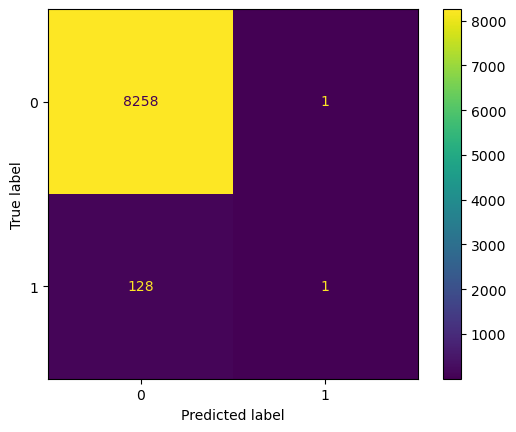

In [14]:
rf = RandomForestClassifier(random_state=42)


rf.fit(X_train, y_train)
y_pred = rf.predict(X_val)

ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
print(classification_report(y_val, y_pred))

Hyperparameters tunen met cross validation


In [15]:
pipe = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(random_state=42)),
])

In [16]:
param_dist = {
    "model__n_estimators": randint(100, 500),
    "model__max_depth": randint(3, 25),
    "model__min_samples_leaf": randint(1, 30),
    "model__min_samples_split": randint(2, 30),
    "model__max_features": ["sqrt", "log2", 0.3, 0.5],
    "model__class_weight": ["balanced", "balanced_subsample"],
}

search = RandomizedSearchCV(
    pipe,
    param_dist,
    n_iter=30,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
)

#search.fit(X_train, y_train)

validatietest

              precision    recall  f1-score   support

           0       0.99      0.90      0.94      8259
           1       0.08      0.53      0.13       129

    accuracy                           0.89      8388
   macro avg       0.53      0.71      0.54      8388
weighted avg       0.98      0.89      0.93      8388



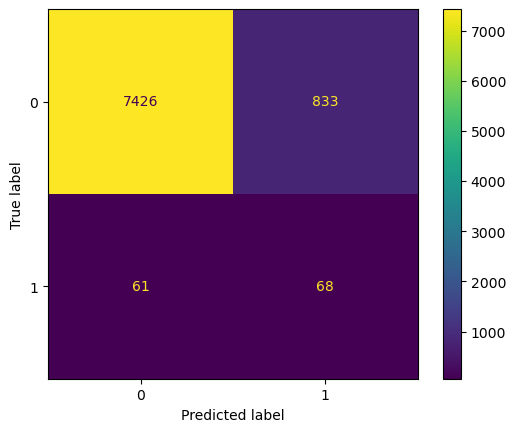

In [17]:
rf2 = RandomForestClassifier(class_weight='balanced', max_depth=23, max_features=0.3,
                       min_samples_leaf=26, min_samples_split=20,
                       n_estimators=314, random_state=42)

rf2.fit(X_train, y_train)
y_pred = rf2.predict(X_val)
ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
print(classification_report(y_val, y_pred))

kaggle submit

In [18]:
rf2.fit(X_train_final, y_train_final)
y_pred = rf2.predict(X_test_final)

submission = pd.DataFrame({
    'id': test_ids,
    'stroke': y_pred,
})
#submission.to_csv('submission_random_forest.csv', index=False)

----

Threshold binnen hyperparameter tunen?

In [19]:
from imblearn.pipeline import Pipeline            # niet die van sklearn, anders werkt SMOTE niet in de pipeline
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    RandomizedSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
    TunedThresholdClassifierCV,
)
from scipy.stats import randint

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

pipe = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(random_state=42)),
])

tuned = TunedThresholdClassifierCV(
    estimator=pipe,
    scoring="f1",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    thresholds=100,
    refit=True,
)

param_dist = {
    "estimator__model__n_estimators": randint(100, 500),
    "estimator__model__max_depth": randint(3, 25),
    "estimator__model__min_samples_leaf": randint(1, 30),
    "estimator__model__min_samples_split": randint(2, 30),
    "estimator__model__max_features": ["sqrt", "log2", 0.3, 0.5],
    "estimator__model__class_weight": ["balanced", "balanced_subsample"],
}

search = RandomizedSearchCV(
    tuned,
    param_dist,
    n_iter=30,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
)

search.fit(X_train, y_train)
print(search.best_params_)
print(search.best_estimator_.best_threshold_)

c:\Users\schur\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Het systeem kan het opgegeven bestand niet vinden
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\schur\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\schur\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\schur\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^

{'estimator__model__class_weight': 'balanced_subsample', 'estimator__model__max_depth': 4, 'estimator__model__max_features': 'sqrt', 'estimator__model__min_samples_leaf': 16, 'estimator__model__min_samples_split': 24, 'estimator__model__n_estimators': 161}
0.6905945215092589


In [ ]:

rf.fit(X_train_final, y_train_final)
proba_test = gb.predict_proba(X_test_final)[:,1]
y_pred = (proba_test >= best_threshold).astype(int)

submission = pd.DataFrame({
    'id': test_ids,
    'stroke': y_pred,
})
submission.to_csv('submission_GBtree.csv', index=False)

----

## Gradient Boosted Trees

standaard

              precision    recall  f1-score   support

           0       1.00      0.98      0.99      8380
           1       0.01      0.12      0.01         8

    accuracy                           0.98      8388
   macro avg       0.50      0.55      0.50      8388
weighted avg       1.00      0.98      0.99      8388



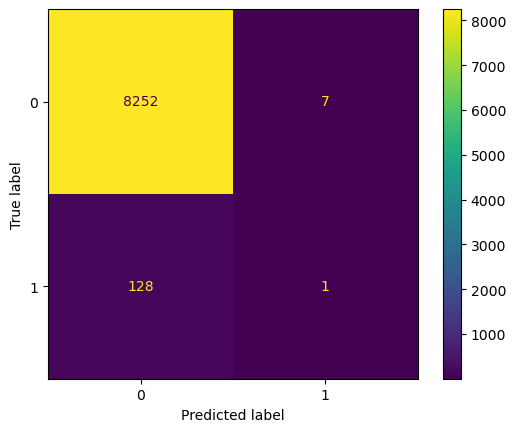

In [20]:
gb = GradientBoostingClassifier(random_state=42)

gb.fit(X_train, y_train)

y_pred = gb.predict(X_val)



ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
print(classification_report(y_pred, y_val))

In [21]:
gb = GradientBoostingClassifier(
    n_iter_no_change=20,        
    validation_fraction=0.1,
    random_state=42,
)

param_dist = {
    "learning_rate": loguniform(0.01, 0.2),
    "n_estimators": randint(200, 1500),    # werkt als maximum door early stopping
    "max_depth": randint(2, 7),
    "min_samples_leaf": randint(5, 60),
    "subsample": uniform(0.6, 0.4),        # 0.6 tot 1.0
    "max_features": uniform(0.4, 0.6),     # 0.4 tot 1.0 (fractie)
    "min_impurity_decrease": uniform(0, 0.01),
}



search = RandomizedSearchCV(
    estimator=gb,
    param_distributions=param_dist,
    n_iter=40,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
)

#search.fit(X_train, y_train)

              precision    recall  f1-score   support

           0       1.00      0.98      0.99      8388
           1       0.00      0.00      0.00         0

    accuracy                           0.98      8388
   macro avg       0.50      0.49      0.50      8388
weighted avg       1.00      0.98      0.99      8388



c:\Users\schur\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\schur\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\schur\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


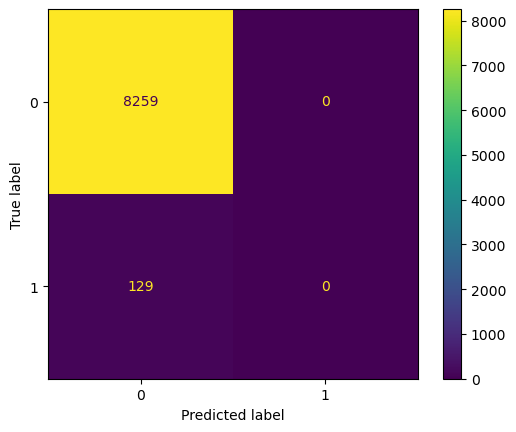

In [22]:
gb = GradientBoostingClassifier(learning_rate=0.017987863473362915, max_depth=2,
                           max_features=0.9767032146096095,
                           min_impurity_decrease=0.008445338486781515,
                           min_samples_leaf=49, n_estimators=537,
                           n_iter_no_change=20, random_state=42,
                           subsample=0.815876852955632)

gb.fit(X_train, y_train)

y_pred = gb.predict(X_val)



ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
print(classification_report(y_pred, y_val))

In [23]:

best_threshold = threshold_finder(gb, X_val, y_val)
print(f"Drempel: {best_threshold:.3f}, validatie-F1: {f1[idx]:.3f}")

NameError: name 'f1' is not defined

In [ ]:
proba_val = gb.predict_proba(X_val)[:,1]

gb_val = (proba_val >= best_threshold).astype(int)

print(classification_report(gb_val, y_val))


              precision    recall  f1-score   support

           0       0.87      0.99      0.93      7266
           1       0.67      0.08      0.14      1122

    accuracy                           0.87      8388
   macro avg       0.77      0.54      0.53      8388
weighted avg       0.85      0.87      0.82      8388



In [ ]:
gb.fit(X_train_final, y_train_final)
proba_test = gb.predict_proba(X_test_final)[:,1]
y_pred = (proba_test >= best_threshold).astype(int)

submission = pd.DataFrame({
    'id': test_ids,
    'stroke': y_pred,
})
submission.to_csv('submission_GBtree.csv', index=False)